# 03 — Model Training

Two-stage transfer learning pipeline using **EfficientNetV2-S**:

**Stage 1 — EyePACS pre-training** (3-phase progressive unfreezing):
- **Phase 1**: Head-only with light augmentation (frozen backbone)
- **Phase 2**: Last block unfrozen (`blocks[-1:]`) with full augmentation + Mixup
- **Phase 3**: Full unfreeze with full augmentation + Mixup

Key features:
- Patient-level stratified splitting (no data leakage)
- Combined loss: Ordinal cross-entropy + Focal loss
- Exponential Moving Average (EMA)
- Cosine LR with warmup + discriminative LR
- Checkpointing on Quadratic Weighted Kappa (QWK)
- **AMP**: `Trainer` uses `config.AMP_DTYPE` (default **bfloat16** on CUDA when supported; else float16 + GradScaler). Override with env `DR_AMP_DTYPE=float16` if needed.

Recommended project flow: this notebook → `03b_aptos_finetuning.ipynb` → `04_evaluation.ipynb`. A JSON run manifest is merged under `outputs/logs/run_manifest.json`.


In [1]:
import importlib
import os
import sys

IS_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in dir() else False

if IS_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = "/content/drive/MyDrive/diabetic_retinopathy"
    %pip install -q timm albumentations kaggle scipy
else:
    PROJECT_ROOT = os.path.abspath("..")

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import src.config
importlib.reload(src.config)
from src import config
config.ensure_dirs()


In [2]:
import pandas as pd
import torch

from src.augmentations import get_light_train_transforms, get_train_transforms, get_valid_transforms
from src.dataset import (
    compute_class_weights,
    create_dataloaders,
    load_and_split_dataframe,
    preprocess_images_to_cache,
)
from src.model import (
    ModelEMA,
    build_model,
    count_parameters,
    freeze_backbone,
    unfreeze_backbone,
)
from src.trainer import Trainer
from src.utils import get_device, log_gpu_memory, seed_everything, write_run_manifest

seed_everything()
device = get_device()
log_gpu_memory("Initial")

write_run_manifest(
    config.RUN_MANIFEST_PATH,
    {
        "stage": "eyepacs",
        "notebook": "03_training",
        "AMP_DTYPE": config.AMP_DTYPE,
        "MODEL_NAME": config.MODEL_NAME,
        "STAGE1_BATCH_SIZE": config.STAGE1_BATCH_SIZE,
        "PREPROCESSING_CACHE_VERSION": config.PREPROCESSING_CACHE_VERSION,
    },
    merge=True,
)


Using GPU: NVIDIA H200 (150.1 GB)
Initial | GPU Memory — Allocated: 0.00GB | Reserved: 0.00GB | Total: 150.1GB


## 1. Data Preparation


In [3]:
# Load and split EyePACS dataset (patient-level stratification)
train_df, valid_df, test_df = load_and_split_dataframe(dataset_name="eyepacs")

print(f'Train : {len(train_df):,} images  ({train_df["patient_id"].nunique():,} patients)')
print(f'Valid : {len(valid_df):,} images  ({valid_df["patient_id"].nunique():,} patients)')
print(f'Test  : {len(test_df):,} images  ({test_df["patient_id"].nunique():,} patients)')
print('\nTrain class distribution:')
print(train_df["level"].value_counts().sort_index())


2026-05-08 06:20:47 | src.dataset | INFO | Using original EyePACS labels: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/trainLabels_cropped.csv


Train : 24,574 images  (12,292 patients)
Valid : 5,267 images  (2,634 patients)
Test  : 5,267 images  (2,635 patients)

Train class distribution:
level
0    18059
1     1702
2     3707
3      613
4      493
Name: count, dtype: int64


## 2. Preprocessing Cache + DataLoaders

Images are preprocessed once (crop + CLAHE + Ben Graham at 384x384) and cached to disk.
`DRDataset` auto-detects the cache and reads directly from it (~6x speedup).

Two sets of loaders:
- `loaders_light`: light augmentation for Phase 1 (head-only)
- `loaders_heavy`: full augmentation for Phase 2/3 (fine-tuning)


In [4]:
# Build preprocessing cache (runs once, skips existing images)
print("Building/verifying preprocessed cache...")
preprocess_images_to_cache(train_df, dataset_name="eyepacs")
preprocess_images_to_cache(valid_df, dataset_name="eyepacs")
print("Cache ready.")

Building/verifying preprocessed cache...


2026-05-08 06:29:48 | src.dataset | INFO | Cache build complete: 24574 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-05-08 06:29:48 | src.dataset | INFO | Cache metadata mismatch detected in /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs; forcing refresh.
2026-05-08 06:31:44 | src.dataset | INFO | Cache build complete: 5267 written, 0 skipped, 0 missing. Cache dir: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs


Cache ready.


In [5]:
# Transforms
light_tfm = get_light_train_transforms(config.STAGE1_IMG_SIZE)
heavy_tfm = get_train_transforms(config.STAGE1_IMG_SIZE)
valid_tfm = get_valid_transforms(config.STAGE1_IMG_SIZE)

# Phase 1 loaders: light augmentation
loaders_light = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    dataset_name="eyepacs",
    train_transform=light_tfm,
    valid_transform=valid_tfm,
    batch_size=config.STAGE1_BATCH_SIZE,
)

# Phase 2/3 loaders: full augmentation
loaders_heavy = create_dataloaders(
    train_df=train_df,
    valid_df=valid_df,
    dataset_name="eyepacs",
    train_transform=heavy_tfm,
    valid_transform=valid_tfm,
    batch_size=config.STAGE1_BATCH_SIZE,
)

print(f"Train batches (light): {len(loaders_light['train'])}")
print(f"Train batches (heavy): {len(loaders_heavy['train'])}")
print(f"Valid batches:         {len(loaders_light['valid'])}")


2026-05-08 06:31:44 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-05-08 06:31:44 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-05-08 06:31:44 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs
2026-05-08 06:31:45 | src.dataset | INFO | Using preprocessed cache: /teamspace/studios/this_studio/diabetic_retinopathy/dataset/preprocessed_384_eyepacs


Train batches (light): 47
Train batches (heavy): 47
Valid batches:         11


## 3. Model + Class Weights


In [6]:
model = build_model(pretrained=True)
params = count_parameters(model)

print(f"Model: {config.MODEL_NAME}")
print(f"Stage1 (EyePACS): {config.STAGE1_IMG_SIZE}x{config.STAGE1_IMG_SIZE} | Stage2 (APTOS): {config.STAGE2_IMG_SIZE}x{config.STAGE2_IMG_SIZE}")
print(f"Total parameters: {params['total']:,}")
print(f"Stochastic depth: {config.STOCHASTIC_DEPTH_RATE}")
print(f"Dropout rate: {config.DROPOUT_RATE}")
print("\nLoss: Combined (OrdinalCE + FocalLoss)")
print(f"  Focal gamma: {config.FOCAL_GAMMA}")
print(f"  Label smoothing: {config.LABEL_SMOOTHING}")
print(f"  Class-weighted: {config.USE_CLASS_WEIGHTED_LOSS}")
print(f"\nMixup: {config.USE_MIXUP} (alpha={config.MIXUP_ALPHA})")
print(f"  Class-conditional: {config.USE_CLASS_CONDITIONAL_MIXUP}")
print(f"\nEMA: {config.USE_EMA} (decay={config.EMA_DECAY})")


model.safetensors:   0%|          | 0.00/86.5M [00:00<?, ?B/s]

Model: tf_efficientnetv2_s.in21k_ft_in1k
Stage1 (EyePACS): 384x384 | Stage2 (APTOS): 512x512
Total parameters: 21,169,238
Stochastic depth: 0.2
Dropout rate: 0.4

Loss: Combined (OrdinalCE + FocalLoss)
  Focal gamma: 2.0
  Label smoothing: 0.1
  Class-weighted: False

Mixup: True (alpha=0.4)
  Class-conditional: True

EMA: True (decay=0.999)


In [7]:
# Class weights for loss function
class_weights = compute_class_weights(train_df["level"].values)
print("Class weights:")
for name, w in zip(config.CLASS_NAMES, class_weights, strict=True):
    print(f"  {name:20s}: {w:.4f}")


Class weights:
  No_DR               : 0.2722
  Mild                : 2.8877
  Moderate            : 1.3258
  Severe              : 8.0176
  Proliferative_DR    : 9.9692


## 4. Stage 1 — EyePACS Training

| Phase | Backbone | Augmentation | LR | WD | Epochs | Mixup |
|-------|----------|-------------|-----|-----|--------|-------|
| 1 | Frozen (head-only) | Light | 1e-3 | 1e-4 | 8 | No |
| 2 | blocks[-1:] (72%) | Full | 5e-5 | 1e-4 | 12 | Yes |
| 3 | Full unfreeze | Full | 1e-5 | 5e-4 | 15 | Yes |

Phase 2/3: head gets 10x the backbone LR (discriminative learning rates).


In [8]:
# Create EMA and Trainer
ema = ModelEMA(model) if config.USE_EMA else None

trainer = Trainer(
    model=model,
    device=device,
    class_weights=class_weights,
    ema=ema,
)

log_gpu_memory("After model init")


2026-05-08 06:31:47 | src.trainer | INFO | AMP dtype=torch.bfloat16 grad_scaler=False


After model init | GPU Memory — Allocated: 0.17GB | Reserved: 0.18GB | Total: 150.1GB


### Phase 1: Head-Only Training


In [9]:
freeze_backbone(model)
print(f"Phase 1 trainable: {count_parameters(model)}")

trainer.fit_phase(
    phase="s1_phase1",
    train_loader=loaders_light["train"],
    valid_loader=loaders_light["valid"],
    epochs=config.STAGE1_PHASE1_EPOCHS + 3,
    lr=config.STAGE1_PHASE1_LR * (config.STAGE1_BATCH_SIZE / 256.0),
    warmup_epochs=3,
    weight_decay=config.STAGE1_PHASE1_WD,
    use_mixup=False,
)

2026-05-08 06:31:48 | src.trainer | INFO | 
2026-05-08 06:31:48 | src.trainer | INFO | Phase: S1_PHASE1 | Epochs: 11 | LR: 0.002 | Mixup: False | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-05-08 06:31:48 | src.trainer | INFO | ============================================================


Phase 1 trainable: {'total': 21169238, 'trainable': 991750, 'frozen': 20177488, 'trainable_pct': 4.6848639521176905}


2026-05-08 06:32:39 | src.trainer | INFO | Epoch 01/11 (51s) | LR: 6.67e-04 | Train Loss: 1.4056 Acc: 0.2945 QWK: 0.2908 | Val Loss: 1.0354 Acc: 0.7135 QWK: 0.0072
2026-05-08 06:32:39 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (QWK=0.0072)
2026-05-08 06:33:14 | src.trainer | INFO | Epoch 02/11 (35s) | LR: 1.33e-03 | Train Loss: 1.2927 Acc: 0.3542 QWK: 0.4395 | Val Loss: 1.0284 Acc: 0.7177 QWK: 0.0122
2026-05-08 06:33:15 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (QWK=0.0122)
2026-05-08 06:33:49 | src.trainer | INFO | Epoch 03/11 (34s) | LR: 2.00e-03 | Train Loss: 1.2506 Acc: 0.3656 QWK: 0.4582 | Val Loss: 1.0321 Acc: 0.7163 QWK: 0.0398
2026-05-08 06:33:49 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (QWK=0.0

True

### Phase 2: Partial Unfreeze (Last Block)


In [10]:
trainer.load_best_checkpoint(phase="s1_phase1")
unfreeze_backbone(model, from_block=config.STAGE1_PHASE2_UNFREEZE)
print(f"Phase 2 trainable: {count_parameters(model)}")

trainer.fit_phase(
    phase="s1_phase2",
    train_loader=loaders_heavy["train"],
    valid_loader=loaders_heavy["valid"],
    epochs=config.STAGE1_PHASE2_EPOCHS,
    lr=config.STAGE1_PHASE2_LR,
    weight_decay=config.STAGE1_PHASE2_WD,
    warmup_epochs=2,
    use_mixup=config.USE_MIXUP,
)

2026-05-08 06:38:30 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase1.pth (epoch 11, QWK=0.2828)
2026-05-08 06:38:30 | src.trainer | INFO | 
2026-05-08 06:38:30 | src.trainer | INFO | Phase: S1_PHASE2 | Epochs: 12 | LR: 5e-05 | Mixup: True | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-05-08 06:38:30 | src.trainer | INFO | ============================================================


Phase 2 trainable: {'total': 21169238, 'trainable': 15783726, 'frozen': 5385512, 'trainable_pct': 74.55972671288404}


  Train:   0%|          | 0/47 [00:00<?, ?it/s]

2026-05-08 06:39:10 | src.trainer | INFO | Epoch 01/12 (40s) | LR: backbone=2.50e-05 head=2.50e-04 | Train Loss: 1.1575 Acc: 0.3648 QWK: 0.4326 | Val Loss: 0.9487 Acc: 0.6818 QWK: 0.2995
2026-05-08 06:39:10 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase2.pth (QWK=0.2995)
2026-05-08 06:39:47 | src.trainer | INFO | Epoch 02/12 (37s) | LR: backbone=5.00e-05 head=5.00e-04 | Train Loss: 1.0975 Acc: 0.3966 QWK: 0.5314 | Val Loss: 0.9366 Acc: 0.6805 QWK: 0.3093
2026-05-08 06:39:47 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase2.pth (QWK=0.3093)
2026-05-08 06:40:22 | src.trainer | INFO | Epoch 03/12 (35s) | LR: backbone=4.88e-05 head=4.88e-04 | Train Loss: 1.0649 Acc: 0.4188 QWK: 0.5718 | Val Loss: 0.9273 Acc: 0.6782 QWK: 0.3219
2026-05-08 06:40:23 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabe

True

### Phase 3: Full Unfreeze


In [11]:
trainer.load_best_checkpoint(phase="s1_phase2")
unfreeze_backbone(model, from_block=None)
print(f"Phase 3 trainable: {count_parameters(model)}")

trainer.fit_phase(
    phase="s1_phase3",
    train_loader=loaders_heavy["train"],
    valid_loader=loaders_heavy["valid"],
    epochs=config.STAGE1_PHASE3_EPOCHS,
    lr=config.STAGE1_PHASE3_LR,
    weight_decay=config.STAGE1_PHASE3_WD,
    warmup_epochs=2,
    use_mixup=config.USE_MIXUP,
)

2026-05-08 06:45:55 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase2.pth (epoch 8, QWK=0.3840)
2026-05-08 06:45:55 | src.trainer | INFO | 
2026-05-08 06:45:55 | src.trainer | INFO | Phase: S1_PHASE3 | Epochs: 15 | LR: 5e-05 | Mixup: True | AMP: True (dtype=torch.bfloat16, scaler=False)
2026-05-08 06:45:55 | src.trainer | INFO | ============================================================


Phase 3 trainable: {'total': 21169238, 'trainable': 21015366, 'frozen': 153872, 'trainable_pct': 99.27313396920569}


  Train:   0%|          | 0/47 [00:00<?, ?it/s]

2026-05-08 06:47:08 | src.trainer | INFO | Epoch 01/15 (73s) | LR: backbone=2.50e-05 head=2.50e-04 | Train Loss: 1.0500 Acc: 0.4176 QWK: 0.5940 | Val Loss: 0.9150 Acc: 0.6134 QWK: 0.3873
2026-05-08 06:47:08 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (QWK=0.3873)
2026-05-08 06:48:09 | src.trainer | INFO | Epoch 02/15 (61s) | LR: backbone=5.00e-05 head=5.00e-04 | Train Loss: 0.9448 Acc: 0.4848 QWK: 0.6928 | Val Loss: 0.9102 Acc: 0.6136 QWK: 0.3964
2026-05-08 06:48:09 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (QWK=0.3964)
2026-05-08 06:49:12 | src.trainer | INFO | Epoch 03/15 (63s) | LR: backbone=4.93e-05 head=4.93e-04 | Train Loss: 0.8833 Acc: 0.5168 QWK: 0.7153 | Val Loss: 0.9145 Acc: 0.6032 QWK: 0.4012
2026-05-08 06:49:12 | src.trainer | INFO | Checkpoint saved: /teamspace/studios/this_studio/diabe

False

## 5. Training Curves


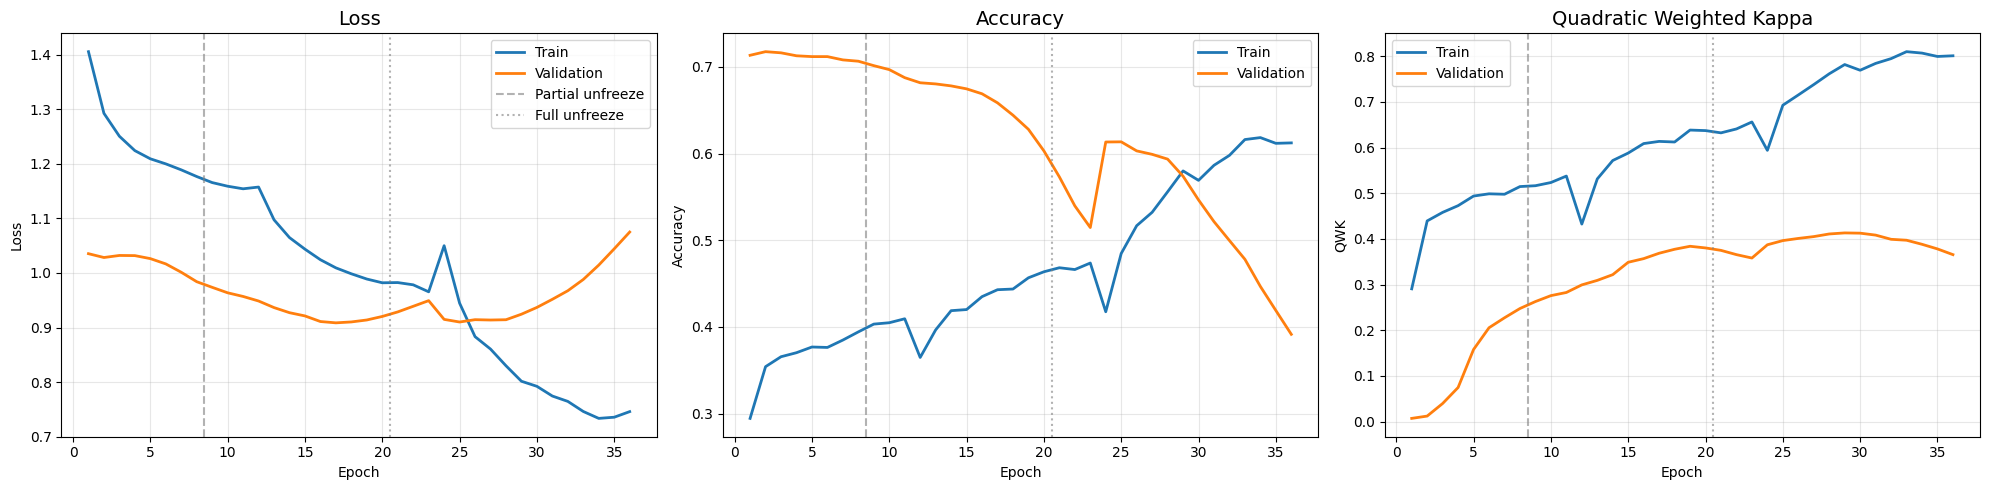

2026-05-08 06:59:41 | src.trainer | INFO | Training history saved to /teamspace/studios/this_studio/diabetic_retinopathy/outputs/logs/stage1_history.json


In [12]:
from src.evaluate import plot_training_curves

plot_training_curves(
    trainer.history,
    save_path=os.path.join(config.FIGURES_DIR, "stage1_training_curves.png"),
    phase_boundaries=[
        config.STAGE1_PHASE1_EPOCHS,
        config.STAGE1_PHASE1_EPOCHS + config.STAGE1_PHASE2_EPOCHS,
    ],
)

trainer.save_history(os.path.join(config.LOGS_DIR, "stage1_history.json"))


## 6. Quick Validation


In [13]:
from src.evaluate import compute_metrics, predict

trainer.load_best_checkpoint("s1_phase3")

if ema is not None:
    ema.apply(model)
    print("Applied EMA weights")

y_true, y_pred, y_proba = predict(model, loaders_heavy["valid"], device)
metrics = compute_metrics(y_true, y_pred, y_proba)

print(f"Validation QWK      : {metrics['qwk']:.4f}")
print(f"Validation Accuracy : {metrics['accuracy']:.4f}")
print(f"Validation ROC-AUC  : {metrics['roc_auc_weighted']:.4f}")
print(f"\n{metrics['classification_report_str']}")


2026-05-08 06:59:42 | src.trainer | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (epoch 6, QWK=0.4132)


Applied EMA weights


Validation QWK      : 0.4140
Validation Accuracy : 0.5743
Validation ROC-AUC  : 0.7149

                  precision    recall  f1-score   support

           No_DR     0.8301    0.6676    0.7400      3863
            Mild     0.1017    0.1936    0.1333       377
        Moderate     0.2700    0.3219    0.2937       786
          Severe     0.2248    0.5188    0.3136       133
Proliferative_DR     0.2576    0.4722    0.3333       108

        accuracy                         0.5743      5267
       macro avg     0.3368    0.4348    0.3628      5267
    weighted avg     0.6673    0.5743    0.6109      5267



## 7. Save Test Split


In [14]:
test_csv_path = os.path.join(config.OUTPUTS_DIR, "test_split_eyepacs.csv")
test_df.to_csv(test_csv_path, index=False)
print(f"Test split saved: {test_csv_path} ({len(test_df)} images)")


Test split saved: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/test_split_eyepacs.csv (5267 images)


## 8. ONNX Export

Export the best model to ONNX for production deployment.


In [16]:
from src.export import export_to_onnx

onnx_path = export_to_onnx(
    checkpoint_path=os.path.join(config.CHECKPOINTS_DIR, "best_model_s1_phase3.pth"), opset_version=18
)
print(f"\nONNX model exported to: {onnx_path}")


2026-05-08 07:00:37 | src.export | INFO | Loaded checkpoint: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/best_model_s1_phase3.pth (epoch 5, QWK=0.4132446247128633)
/teamspace/studios/this_studio/diabetic_retinopathy/src/export.py:75: UserWarning: # 'dynamic_axes' is not recommended when dynamo=True, and may lead to 'torch._dynamo.exc.UserError: Constraints violated.' Supply the 'dynamic_shapes' argument instead if export is unsuccessful.
  torch.onnx.export(


[torch.onnx] Obtain model graph for `DRModel([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DRModel([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/system/conda/miniconda3/uv/python/cpython-3.12.11-linux-x86_64-gnu/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


2026-05-08 07:00:49 | src.export | INFO | ONNX validation passed (max diff: 6.56e-07)
2026-05-08 07:00:49 | src.export | INFO | ONNX model exported: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx (81.8 MB, opset 18)



ONNX model exported to: /teamspace/studios/this_studio/diabetic_retinopathy/outputs/checkpoints/model.onnx


## 9. Next Steps

Stage 1 (EyePACS pre-training) complete. Continue with:
Proceed to `03b_aptos_finetuning.ipynb` next.
- `04_evaluation.ipynb` for full evaluation
- `05_gradcam.ipynb` for explainability